This script showcases various methods of regression, beginning with the simplest, and progressing in complexity.

In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
result_dict = {}

# Get data

In [6]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/alinoranianesfahani/dataco-smart-supply-chain-for-big-data-analysis/code
    
# load single-store sales data
DataCoSupplyChainDataset = pd.read_csv(
    data_dir / 'DataCoSupplyChainDataset.csv',
    encoding='Latin-1',
    low_memory=False
)

# Wrangle

In [7]:
# load the dataset
df = DataCoSupplyChainDataset.copy()

# prepare numeric columns
numeric_cols = [
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Days for shipment (scheduled)",
    "Late_delivery_risk"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["order_date"] = pd.to_datetime(
    df["order date (DateOrders)"], errors="coerce"
)

# remove rows missing essential values
df = df.dropna(
    subset=[
        "Order Item Quantity",
        "Order Item Product Price",
        "Order Item Discount",
        "Days for shipment (scheduled)",
        "Late_delivery_risk",
        "order_date"
    ]
).copy()

# Split into train and test

In [8]:
# define a shared regression target and feature set
target = "Order Item Quantity"
features = [
    "Order Item Product Price",
    "Order Item Discount",
    "Days for shipment (scheduled)"
]

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fit several models
Use a few features to prodict the Order Item Quantity

In [9]:
# define a common regression evaluation function
def evaluate_regression(name, model, X_test, y_test):
    predictions = model.predict(X_test)

    return {
        "model": name,
        "mae": mean_absolute_error(y_test, predictions),
        "rmse": np.sqrt(mean_squared_error(y_test, predictions)),
        "r2": r2_score(y_test, predictions)
    }

In [10]:
# 1. baseline modeling
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_results = evaluate_regression(
    "mean baseline", baseline, X_test, y_test
)

In [11]:
# 2. simple linear regression
simple_feature = ["Order Item Product Price"]

simple_model = LinearRegression()
simple_model.fit(X_train[simple_feature], y_train)

simple_results = evaluate_regression(
    "simple linear regression",
    simple_model,
    X_test[simple_feature],
    y_test
)

In [12]:
# 3. multiple linear regression
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_results = evaluate_regression(
    "multiple linear regression",
    multiple_model,
    X_test,
    y_test
)

In [13]:
# 4. machine learning regression
ml_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

ml_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [14]:
ml_results = evaluate_regression(
    "random forest regression",
    ml_model,
    X_test,
    y_test
)


# display regression comparison
regression_results = pd.DataFrame([
    baseline_results,
    simple_results,
    multiple_results,
    ml_results
])

display(regression_results.sort_values("mae"))

,model,mae,rmse,r2
3,random forest regression,0.454250,0.791795,0.703288
2,multiple linear regression,0.972615,1.171911,0.350021
1,simple linear regression,1.043176,1.273909,0.231955
0,mean baseline,1.269167,1.453634,-0.000046


Best model above would be the random forest model, with the highest r2 and lowest MAE.

# View model results

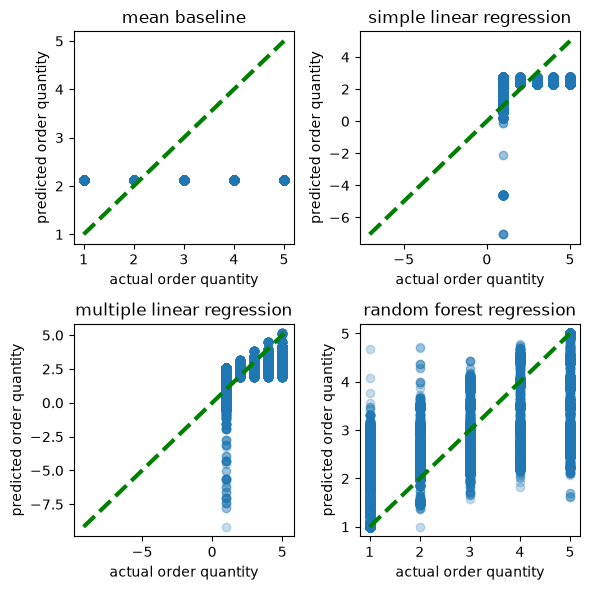

In [15]:
import matplotlib.pyplot as plt

# generate predictions from each model
predictions = {
    "mean baseline": baseline.predict(X_test),
    "simple linear regression": simple_model.predict(X_test[simple_feature]),
    "multiple linear regression": multiple_model.predict(X_test),
    "random forest regression": ml_model.predict(X_test)
}

# plot actual vs. predicted values for each model
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.25)

    # add reference line for perfect predictions
    lower = min(y_test.min(), y_pred.min())
    upper = max(y_test.max(), y_pred.max())
    ax.plot([lower, upper], [lower, upper], linestyle="--", color='green', lw=3)

    ax.set_title(name)
    ax.set_xlabel("actual order quantity")
    ax.set_ylabel("predicted order quantity")

plt.tight_layout()
plt.show()

Dots should cluster near the diagonal line.  
The farther a dot is from the line, the larger the prediction error.


A vertical band of dots means many records have the same actual quantity but the model predicts different values for them.

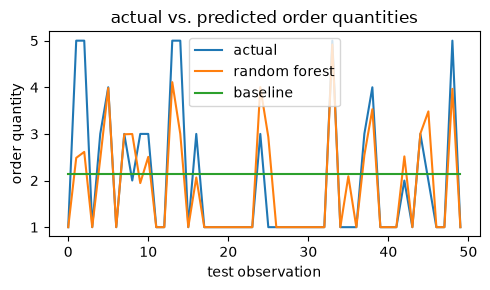

In [16]:
import matplotlib.pyplot as plt

# compare actual and predicted quantities for the first 50 test rows
n = 50

plt.figure(figsize=(5, 3))
plt.plot(y_test.iloc[:n].to_numpy(), label="actual")
plt.plot(ml_model.predict(X_test.iloc[:n]), label="random forest")
plt.plot(baseline.predict(X_test.iloc[:n]), label="baseline")

plt.title("actual vs. predicted order quantities")
plt.xlabel("test observation")
plt.ylabel("order quantity")
plt.legend()
plt.tight_layout()
plt.show()

# ML time series
Time-series ML explicitly accounts for temporal order, using time-based splits and features like lags, rolling averages, and seasonality to predict future values without data leakage.  

Regression typically models relationships between predictors and a target, often using random train/test splits, without necessarily accounting for time.

In [17]:
# aggregate demand by product and date
daily_demand = (
    df.assign(date=df["order_date"].dt.normalize())
    .groupby(["Product Card Id", "date"], as_index=False)[target]
    .sum()
    .rename(columns={
        "Product Card Id": "product_id",
        target: "demand"
    })
)

# create a complete daily calendar for every product
all_dates = pd.date_range(
    daily_demand["date"].min(),
    daily_demand["date"].max(),
    freq="D"
)

products = daily_demand["product_id"].unique()

full_index = pd.MultiIndex.from_product(
    [products, all_dates],
    names=["product_id", "date"]
)

daily_demand = (
    daily_demand.set_index(["product_id", "date"])
    .reindex(full_index, fill_value=0)
    .reset_index()
    .sort_values(["product_id", "date"])
)

# create features using only previous demand
daily_demand["lag_1"] = (
    daily_demand.groupby("product_id")["demand"].shift(1)
)

daily_demand["lag_7"] = (
    daily_demand.groupby("product_id")["demand"].shift(7)
)

daily_demand["rolling_7"] = (
    daily_demand.groupby("product_id")["demand"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

daily_demand["day_of_week"] = daily_demand["date"].dt.dayofweek
daily_demand["month"] = daily_demand["date"].dt.month

daily_demand = daily_demand.dropna().copy()

In [14]:
# split
ts_features = [
    "lag_1",
    "lag_7",
    "rolling_7",
    "day_of_week",
    "month"
]

# use a chronological split to prevent future dates leaking into training
split_date = daily_demand["date"].quantile(0.8)

ts_train = daily_demand[daily_demand["date"] <= split_date]
ts_test = daily_demand[daily_demand["date"] > split_date]

X_ts_train = ts_train[ts_features]
y_ts_train = ts_train["demand"]
X_ts_test = ts_test[ts_features]
y_ts_test = ts_test["demand"]

In [28]:
# note this is the same model as the regressor above
# but here we consider different features than before, and we account for the temporal order of a time-series
ts_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

ts_model.fit(X_ts_train, y_ts_train)
ts_predictions = ts_model.predict(X_ts_test)

ts_results = {
    "model": "random forest time series",
    "mae": mean_absolute_error(y_ts_test, ts_predictions),
    "rmse": np.sqrt(mean_squared_error(y_ts_test, ts_predictions)),
    "r2": r2_score(y_ts_test, ts_predictions)
}

### Compare
Random forest regression vs random forest time series

In [27]:
# the RF regression results
display(regression_results[regression_results.loc[:, 'model']=='random forest regression'])

,model,mae,rmse,r2
3,random forest regression,0.45425,0.791795,0.703288


In [29]:
# the RF time series ressults
# same model, different features and split
display(pd.DataFrame([ts_results]))

,model,mae,rmse,r2
0,random forest time series,0.966674,4.996077,0.696049


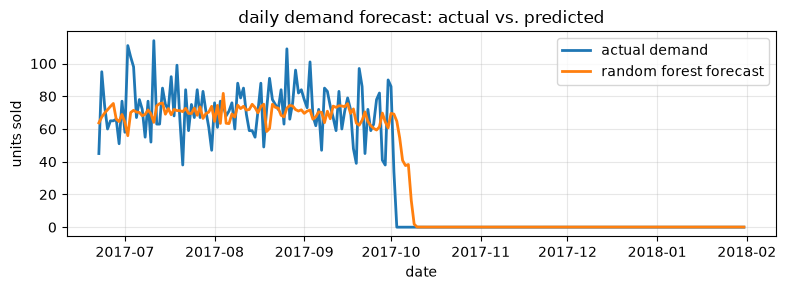

In [31]:
# combine test dates, actual demand, and predictions
ts_plot = ts_test[["date", "product_id", "demand"]].copy()
ts_plot["predicted"] = ts_predictions

# select the product with the most demand for a readable example
product_id = (
    ts_plot.groupby("product_id")["demand"]
    .sum()
    .idxmax()
)

plot_data = (
    ts_plot[ts_plot["product_id"] == product_id]
    .sort_values("date")
)

# plot actual vs. predicted demand
plt.figure(figsize=(8, 3))
plt.plot(
    plot_data["date"],
    plot_data["demand"],
    label="actual demand",
    linewidth=2
)
plt.plot(
    plot_data["date"],
    plot_data["predicted"],
    label="random forest forecast",
    linewidth=2
)

plt.title("daily demand forecast: actual vs. predicted")
plt.xlabel("date")
plt.ylabel("units sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Random forest comparison conclusion
The regression model is the same as the time series model, but the MAE's are different while the R-squared's are similar.  


This suggests that both models explain a similar proportion of the variance, but their absolute prediction errors differ, likely due to differences in the train/test split, temporal features, and evaluation data.

Additionally, next steps should be to understand and most likely remove the trailing zeros; no doubt this affects the models.

# Logistic regression
Logistic regression, despite its name, is a classification algorithm.   
We will model Late_delivery_risk

Logistic regression uses the logit to model the relationship between input variables and the probability of a binary outcome.

The logit is the natural logarithm of the odds of an event occurring. In logistic regression, it transforms a probability (0 to 1) into an unbounded value (negative to positive infinity) so that a linear model can be used.

Odds represent the ratio of an event happening to it not happening.

In [18]:
# use predictors available before delivery
classification_features = [
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Days for shipment (scheduled)",
    "Shipping Mode"
]

classification_target = "Late_delivery_risk"

classification_df = df.dropna(
    subset=classification_features + [classification_target]
).copy()

X_class = classification_df[classification_features]
y_class = classification_df[classification_target].astype(int)

# use a stratified split to preserve the class proportions
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

numeric_features = [
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Days for shipment (scheduled)"
]

categorical_features = ["Shipping Mode"]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(Xc_train, yc_train)

class_predictions = logistic_model.predict(Xc_test)
class_probabilities = logistic_model.predict_proba(Xc_test)[:, 1]

print("logistic regression")
print("accuracy:", round(accuracy_score(yc_test, class_predictions), 3))
print("precision:", round(precision_score(yc_test, class_predictions, zero_division=0), 3))
print("recall:", round(recall_score(yc_test, class_predictions, zero_division=0), 3))
print("f1:", round(f1_score(yc_test, class_predictions, zero_division=0), 3))

if yc_test.nunique() == 2:
    print("roc auc:", round(roc_auc_score(yc_test, class_probabilities), 3))

logistic regression
accuracy: 0.697
precision: 0.85
recall: 0.543
f1: 0.662
roc auc: 0.731


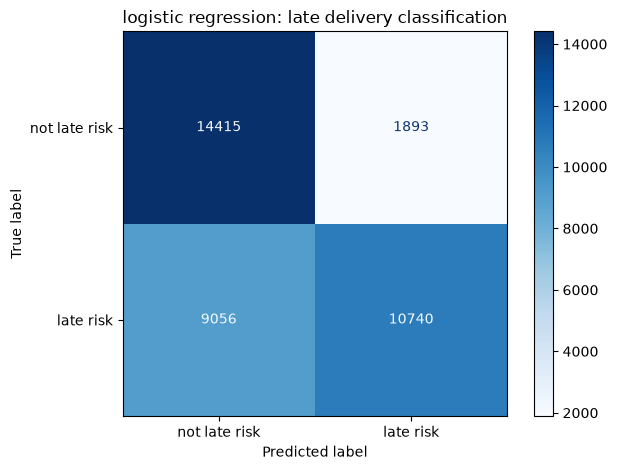

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    yc_test,
    class_predictions,
    display_labels=["not late risk", "late risk"],
    cmap="Blues",
    values_format="d"
)

plt.title("logistic regression: late delivery classification")
plt.tight_layout()
plt.show()

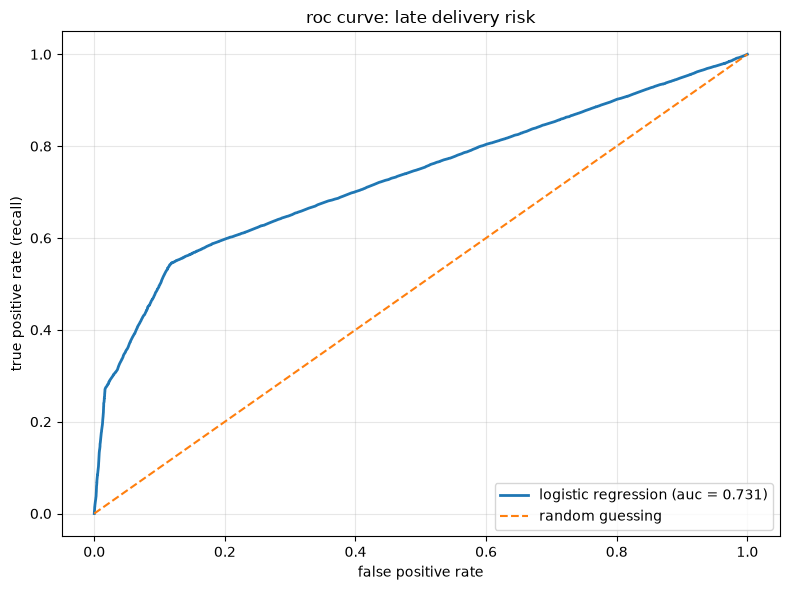

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# calculate the roc curve and auc
fpr, tpr, thresholds = roc_curve(yc_test, class_probabilities)
auc_score = roc_auc_score(yc_test, class_probabilities)

# plot the roc curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"logistic regression (auc = {auc_score:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--", label="random guessing")

plt.title("roc curve: late delivery risk")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate (recall)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusion

At AUC = 0.73, the model is doing pretty well, not amazing, but ok.  
Complete randomness would yield 0.50.  

In the confusion matrix, I see ok precision, but recall could improve.

### Next steps
More features, different features, hyperparameter tuning, training data transformations.  
This model here is a good logistic regression baseline.  
Now let's try and beat it. 

In [21]:
print('done')

done
